# 04 · Indicadores y dimensiones: calidad, redundancia y relaciones exploratorias

**Objetivo.** Examinar la matriz de features país × (indicador × estadístico) antes del modelado: datos faltantes por dimensión, desempeño de la imputación, redundancia interna de cada dimensión (la justificación del PCA) y una primera mirada, exploratoria y no causal, a qué indicadores se asocian con el nivel de inflación.

**Insumos.** `features_crudas.parquet` (antes de imputar), `features_imputadas_z.parquet` (estandarizadas e imputadas por KNN), `imputacion_cv.csv`, `target_principal.csv`.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion import targets
from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
from inflacion.sources.countries import un_members

members = un_members().set_index("iso3")
X = pd.read_parquet(D / "features_crudas.parquet")
Z = pd.read_parquet(D / "features_imputadas_z.parquet")
cov = pd.read_csv(D / "cobertura_indicadores.csv").set_index("codigo")
meta = pd.concat([pd.read_csv(Paths.raw / "wdi" / "wdi_metadata_20261111.csv"),
                  pd.read_csv(Paths.raw / "vdem" / "vdem_79_metadata_v16.csv")]).drop_duplicates("codigo").set_index("codigo")["nombre_indicador"]
meta["hh_market_concentration"] = "Export market concentration (HHI)"
target = pd.read_csv(D / "target_principal.csv", index_col="iso3")
feat = pd.DataFrame({"col": Z.columns})
feat["codigo"] = feat["col"].str.rsplit("__", n=1).str[0]
feat["estadistico"] = feat["col"].str.rsplit("__", n=1).str[1]
feat["dimension"] = feat["codigo"].map(cov["dimension"])
print(f"Matriz: {Z.shape[0]} países × {Z.shape[1]} features ({feat['codigo'].nunique()} indicadores × 3 estadísticos)")
feat.groupby(["dimension", "estadistico"]).size().unstack()

Matriz: 183 países × 1659 features (553 indicadores × 3 estadísticos)


estadistico,media,tendencia,volatilidad
dimension,,,
ESTRUCTURAL,168,168,168
INSTITUCIONAL,85,85,85
MONETARIA,59,59,59
SOCIODEMOGRAFICA,241,241,241


## 1. Datos faltantes antes de la imputación

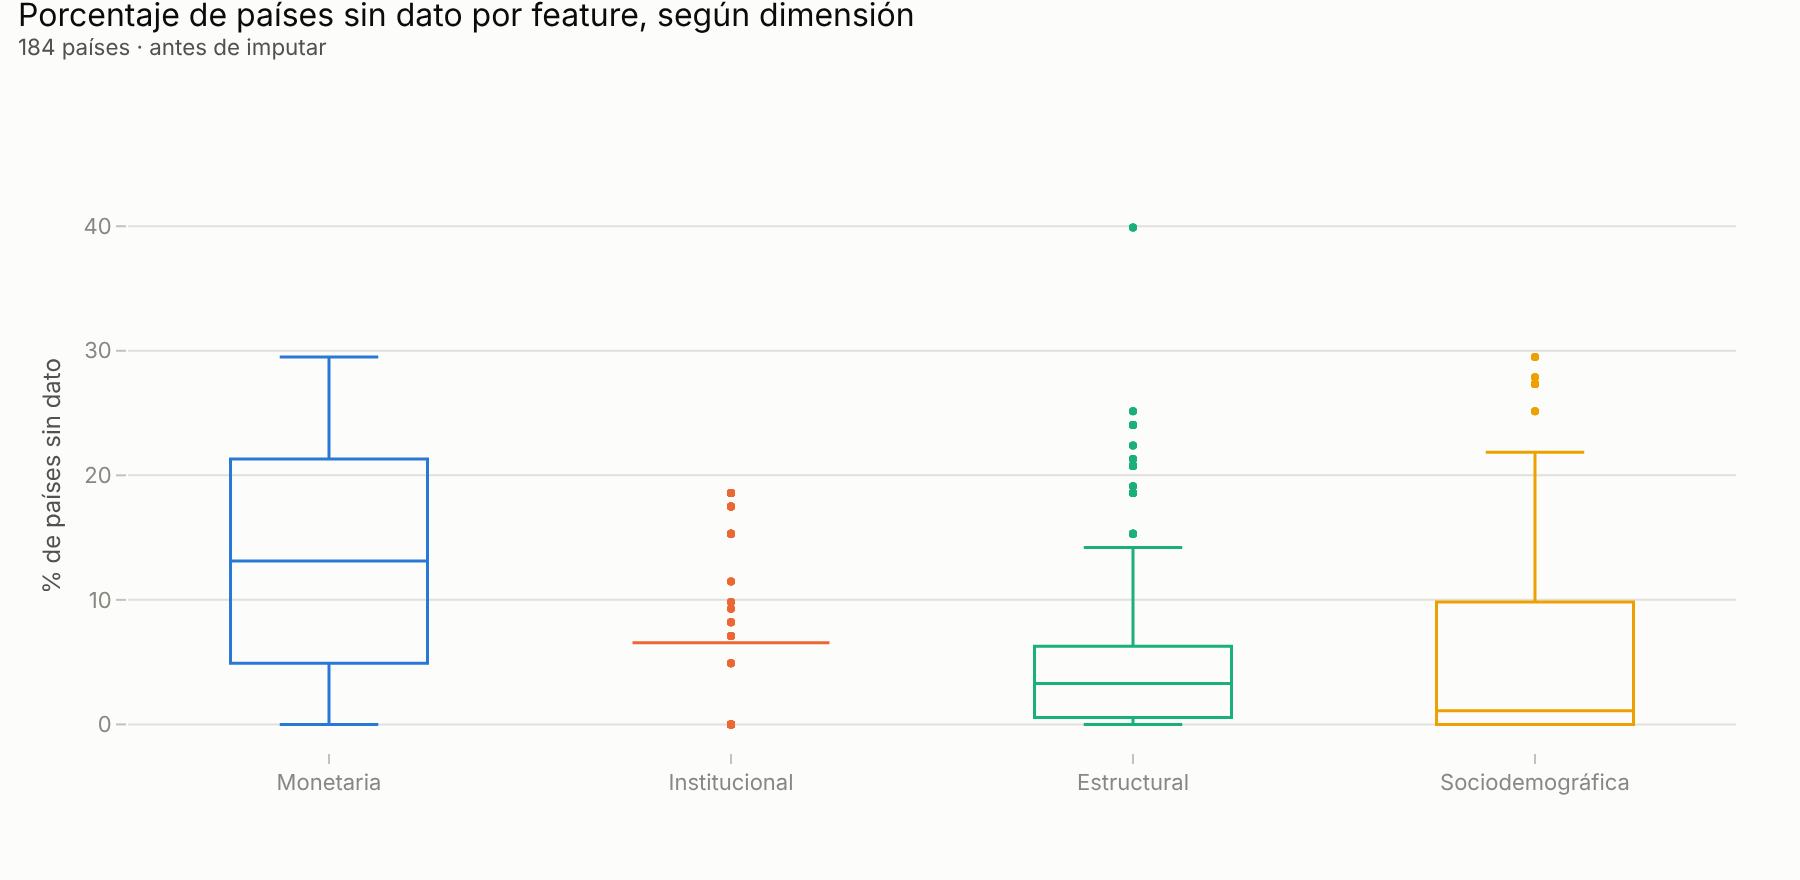

                  mean   50%   75%   max
dimension                               
ESTRUCTURAL        5.4   3.3   6.1  39.9
INSTITUCIONAL      7.0   6.6   6.6  18.6
MONETARIA         13.0  13.1  21.3  29.5
SOCIODEMOGRAFICA   5.1   1.1   9.8  29.5
Faltantes totales: 6.31%


In [2]:
miss = X.isna().mean().mul(100).rename("pct").to_frame().join(feat.set_index("col"))
fig = go.Figure()
for dim, color in DIMENSION_COLORS.items():
    v = miss.loc[miss["dimension"] == dim, "pct"]
    fig.add_box(y=v, name=DIM_LABELS[dim], marker=dict(color=color, size=4), line=dict(color=color, width=1.5),
                fillcolor="rgba(0,0,0,0)", boxpoints="outliers", showlegend=False,
                hovertemplate=DIM_LABELS[dim] + ": %{y:.1f}%<extra></extra>")
fig.update_layout(title=subtitle("Porcentaje de países sin dato por feature, según dimensión", "184 países · antes de imputar"),
                  yaxis_title="% de países sin dato", xaxis=dict(showgrid=False))
show(fig, "04_missing_por_dimension", height=440)
print(miss.groupby("dimension")["pct"].describe()[["mean", "50%", "75%", "max"]].round(1))
print(f"Faltantes totales: {X.isna().mean().mean():.2%}")

**Interpretación.** Los faltantes totales son bajos (6,3% de las celdas), pero no se reparten igual entre dimensiones. La monetaria es la más incompleta (media 13,0%, hasta 29,5% en algunas features): los agregados monetarios, el crédito y las series fiscales se reportan de forma menos sistemática que los indicadores demográficos o de gobernanza. La sociodemográfica tiene una mediana muy baja (1,1%) con una cola de indicadores de encuestas. Esto implica que la imputación pesa más en el bloque monetario, justamente el que se usa para el clustering.

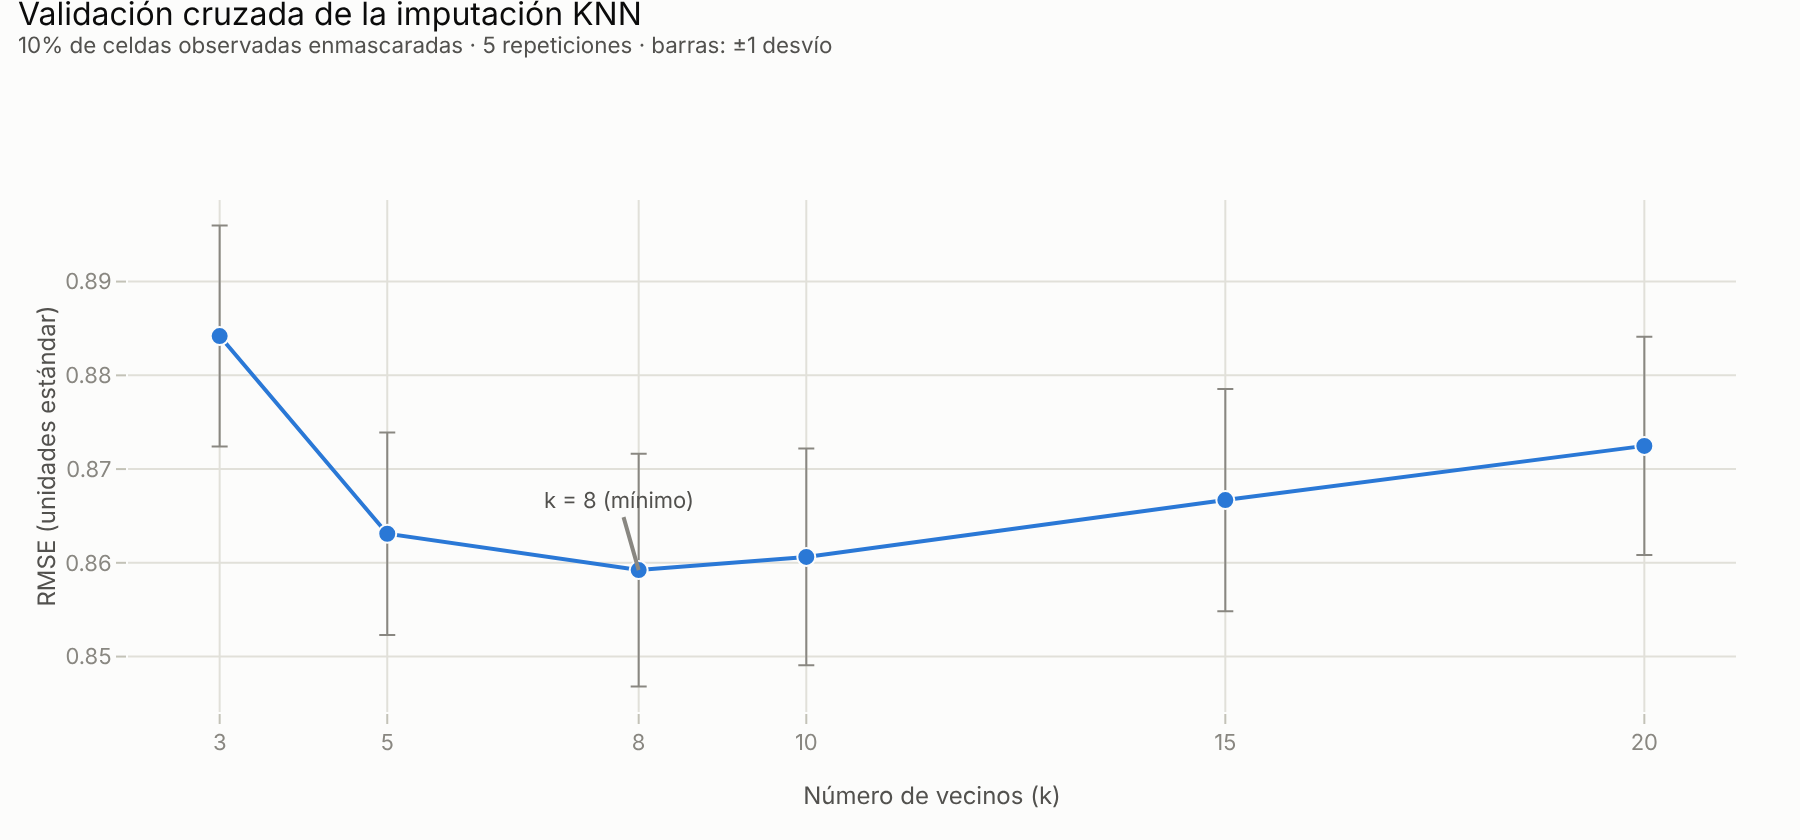

,k,mean,std
5,3,0.884,0.012
2,5,0.863,0.011
0,8,0.859,0.012
1,10,0.861,0.012
3,15,0.867,0.012
4,20,0.873,0.012


In [3]:
cv = pd.read_csv(D / "imputacion_cv.csv").sort_values("k")
best = cv.loc[cv["mean"].idxmin()]
fig = go.Figure(go.Scatter(x=cv["k"], y=cv["mean"], mode="lines+markers", marker=dict(size=9, color=CATEGORICAL[0]),
                           line=dict(color=CATEGORICAL[0]), error_y=dict(type="data", array=cv["std"], color=INK_MUTED, thickness=1),
                           hovertemplate="k=%{x}: RMSE %{y:.3f}<extra></extra>"))
fig.add_annotation(x=best["k"], y=best["mean"], text=f"k = {int(best['k'])} (mínimo)", showarrow=True, arrowhead=0, ay=-35,
                   font=dict(size=11, color=INK_SECONDARY), arrowcolor=INK_MUTED)
fig.update_layout(title=subtitle("Validación cruzada de la imputación KNN", "10% de celdas observadas enmascaradas · 5 repeticiones · barras: ±1 desvío"),
                  xaxis=dict(title="Número de vecinos (k)", tickvals=cv["k"]), yaxis_title="RMSE (unidades estándar)")
show(fig, "04_imputacion_cv", height=420)
cv.round(4)

**Interpretación.** El error de reconstrucción es mínimo en k = 8 (RMSE 0,859 desvíos estándar), pero entre k = 5 y k = 10 las diferencias son menores a un desvío entre repeticiones: la curva es plana en ese rango. Solo k = 3 es claramente peor. La elección de k es, por lo tanto, poco influyente. La tesis eligió k = 5 con el mismo procedimiento, y el resultado es equivalente.

**Limitación.** Un RMSE de 0,86 desvíos significa que la imputación recupera alrededor de un cuarto de la variabilidad de las celdas enmascaradas (1 − 0,86² ≈ 0,26). Los valores imputados tienden al promedio de los países similares y atenúan la varianza. Con 6,3% de faltantes el efecto sobre el PCA es acotado, pero no nulo.

## 2. Redundancia dentro de cada dimensión

Si las variables de una dimensión están muy correlacionadas entre sí, una distancia euclídea (clustering) o una regresión con todas ellas contarían varias veces el mismo fenómeno. El siguiente gráfico muestra la distribución de |r| entre pares de features de la misma dimensión, para el estadístico de nivel (media).

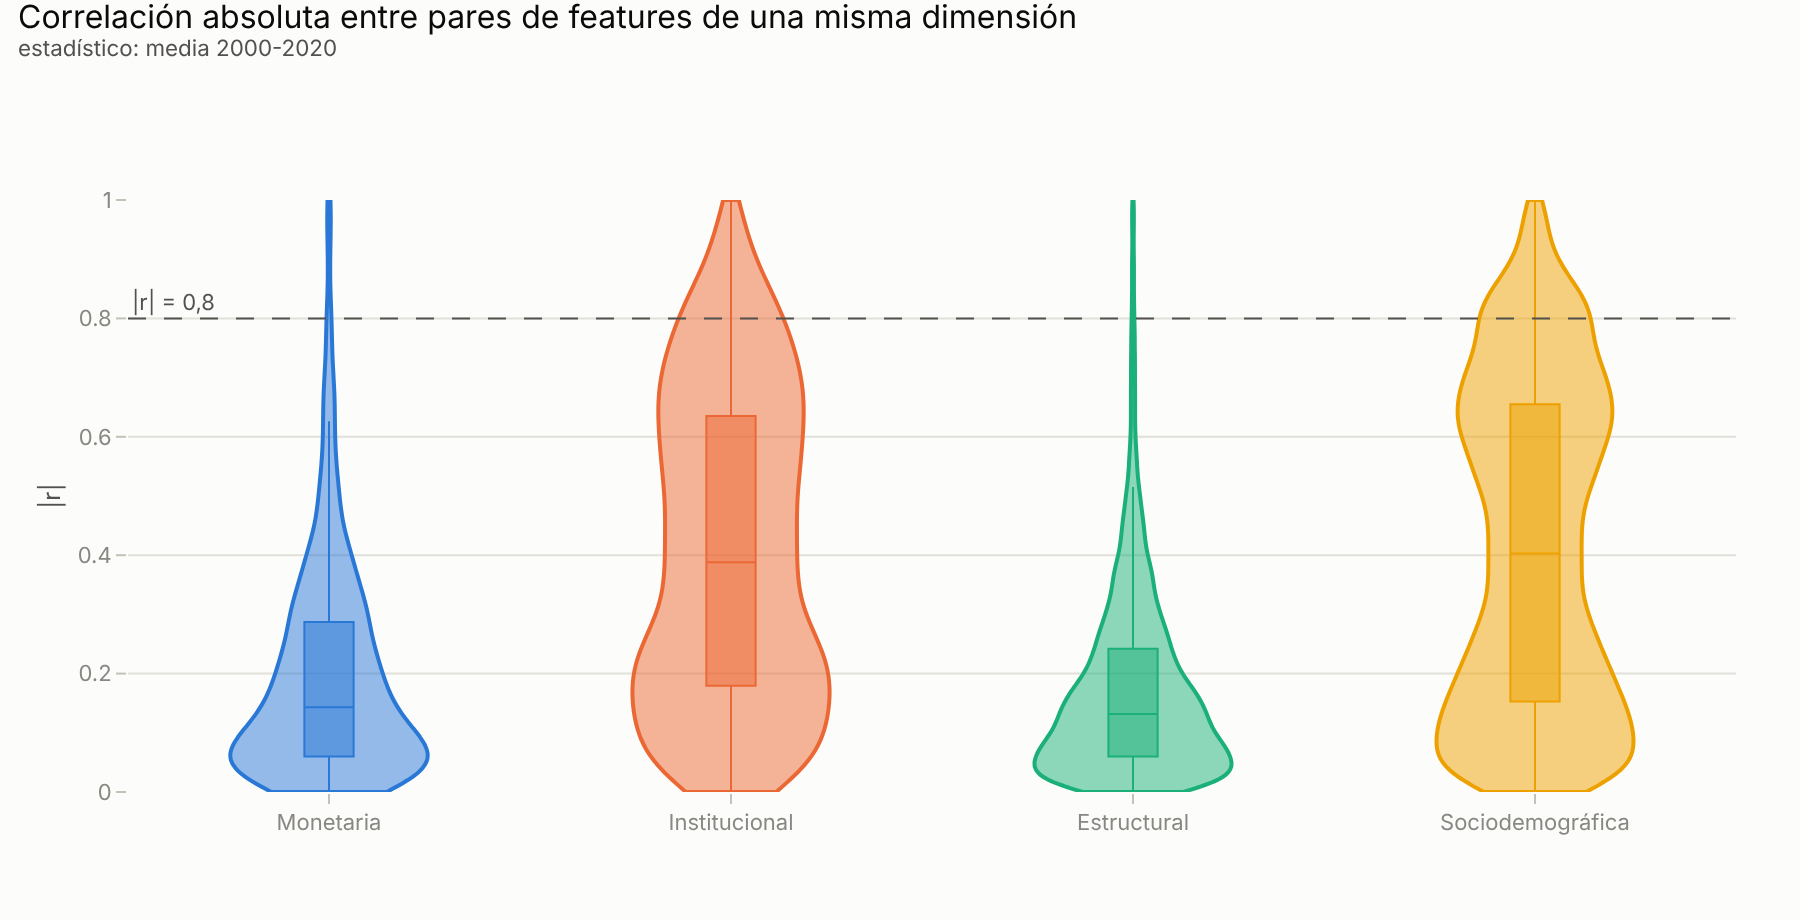

,dimension,n_vars,pares,mediana_abs_r,pct_pares_r_gt_0.8,pct_pares_r_gt_0.95
0,MONETARIA,59,1711,0.143,1.227,0.468
1,INSTITUCIONAL,85,3570,0.388,8.291,1.036
2,ESTRUCTURAL,168,14028,0.132,0.763,0.207
3,SOCIODEMOGRAFICA,241,28920,0.403,9.492,1.107


In [4]:
rows = []
for dim in DIMENSION_COLORS:
    cols = feat.loc[(feat["dimension"] == dim) & (feat["estadistico"] == "media"), "col"]
    C = np.abs(np.corrcoef(Z[cols].to_numpy(), rowvar=False))
    iu = np.triu_indices_from(C, k=1)
    v = C[iu]
    rows.append({"dimension": dim, "n_vars": len(cols), "pares": len(v), "mediana_abs_r": np.median(v),
                 "pct_pares_r_gt_0.8": 100 * (v > 0.8).mean(), "pct_pares_r_gt_0.95": 100 * (v > 0.95).mean()})
    rows[-1]["_v"] = v
red = pd.DataFrame(rows)
fig = go.Figure()
for _, r in red.iterrows():
    fig.add_violin(y=r["_v"], name=DIM_LABELS[r["dimension"]], line_color=DIMENSION_COLORS[r["dimension"]], box_visible=True,
                   meanline_visible=False, points=False, showlegend=False, spanmode="hard")
fig.add_hline(y=0.8, line=dict(color=INK_SECONDARY, dash="dash", width=1))
fig.add_annotation(x=0, xref="paper", y=0.8, text="|r| = 0,8", showarrow=False, xanchor="left", yshift=8, font=dict(size=11, color=INK_SECONDARY))
fig.update_layout(title=subtitle("Correlación absoluta entre pares de features de una misma dimensión", "estadístico: media 2000-2020"),
                  yaxis=dict(title="|r|", range=[0, 1]), xaxis=dict(showgrid=False))
show(fig, "04_redundancia_intra_dimension", height=460)
red.drop(columns="_v").round(3)

**Interpretación.** Las dimensiones difieren mucho en su estructura interna:

- **Institucional y sociodemográfica**: alta redundancia (mediana de |r| ≈ 0,39, con 8-9% de pares por encima de 0,8). Gran parte de sus indicadores reflejan un mismo gradiente: calidad de gobernanza en una, nivel de desarrollo humano en la otra. Su primer componente principal va a concentrar una fracción grande de la varianza.
- **Monetaria y estructural**: baja redundancia (mediana ≈ 0,13-0,14, alrededor de 1% de pares sobre 0,8). Agrupan fenómenos heterogéneos (tasas, crédito, ahorro, fiscalidad; composición sectorial, comercio, tecnología) y van a requerir muchos componentes para resumirse.

En los dos casos el PCA está justificado, aunque por razones distintas: en las dimensiones redundantes evita contar varias veces el mismo fenómeno, y en las heterogéneas reduce la dimensionalidad sin elegir variables a mano.

## 3. Asociaciones exploratorias con el nivel de inflación

Correlación de Spearman entre cada indicador (media 2000-2020, antes de imputar) y la inflación media del período. Se muestran los 6 indicadores de mayor |ρ| por dimensión. **Es una descripción bivariada**: no controla por otras variables ni implica causalidad.

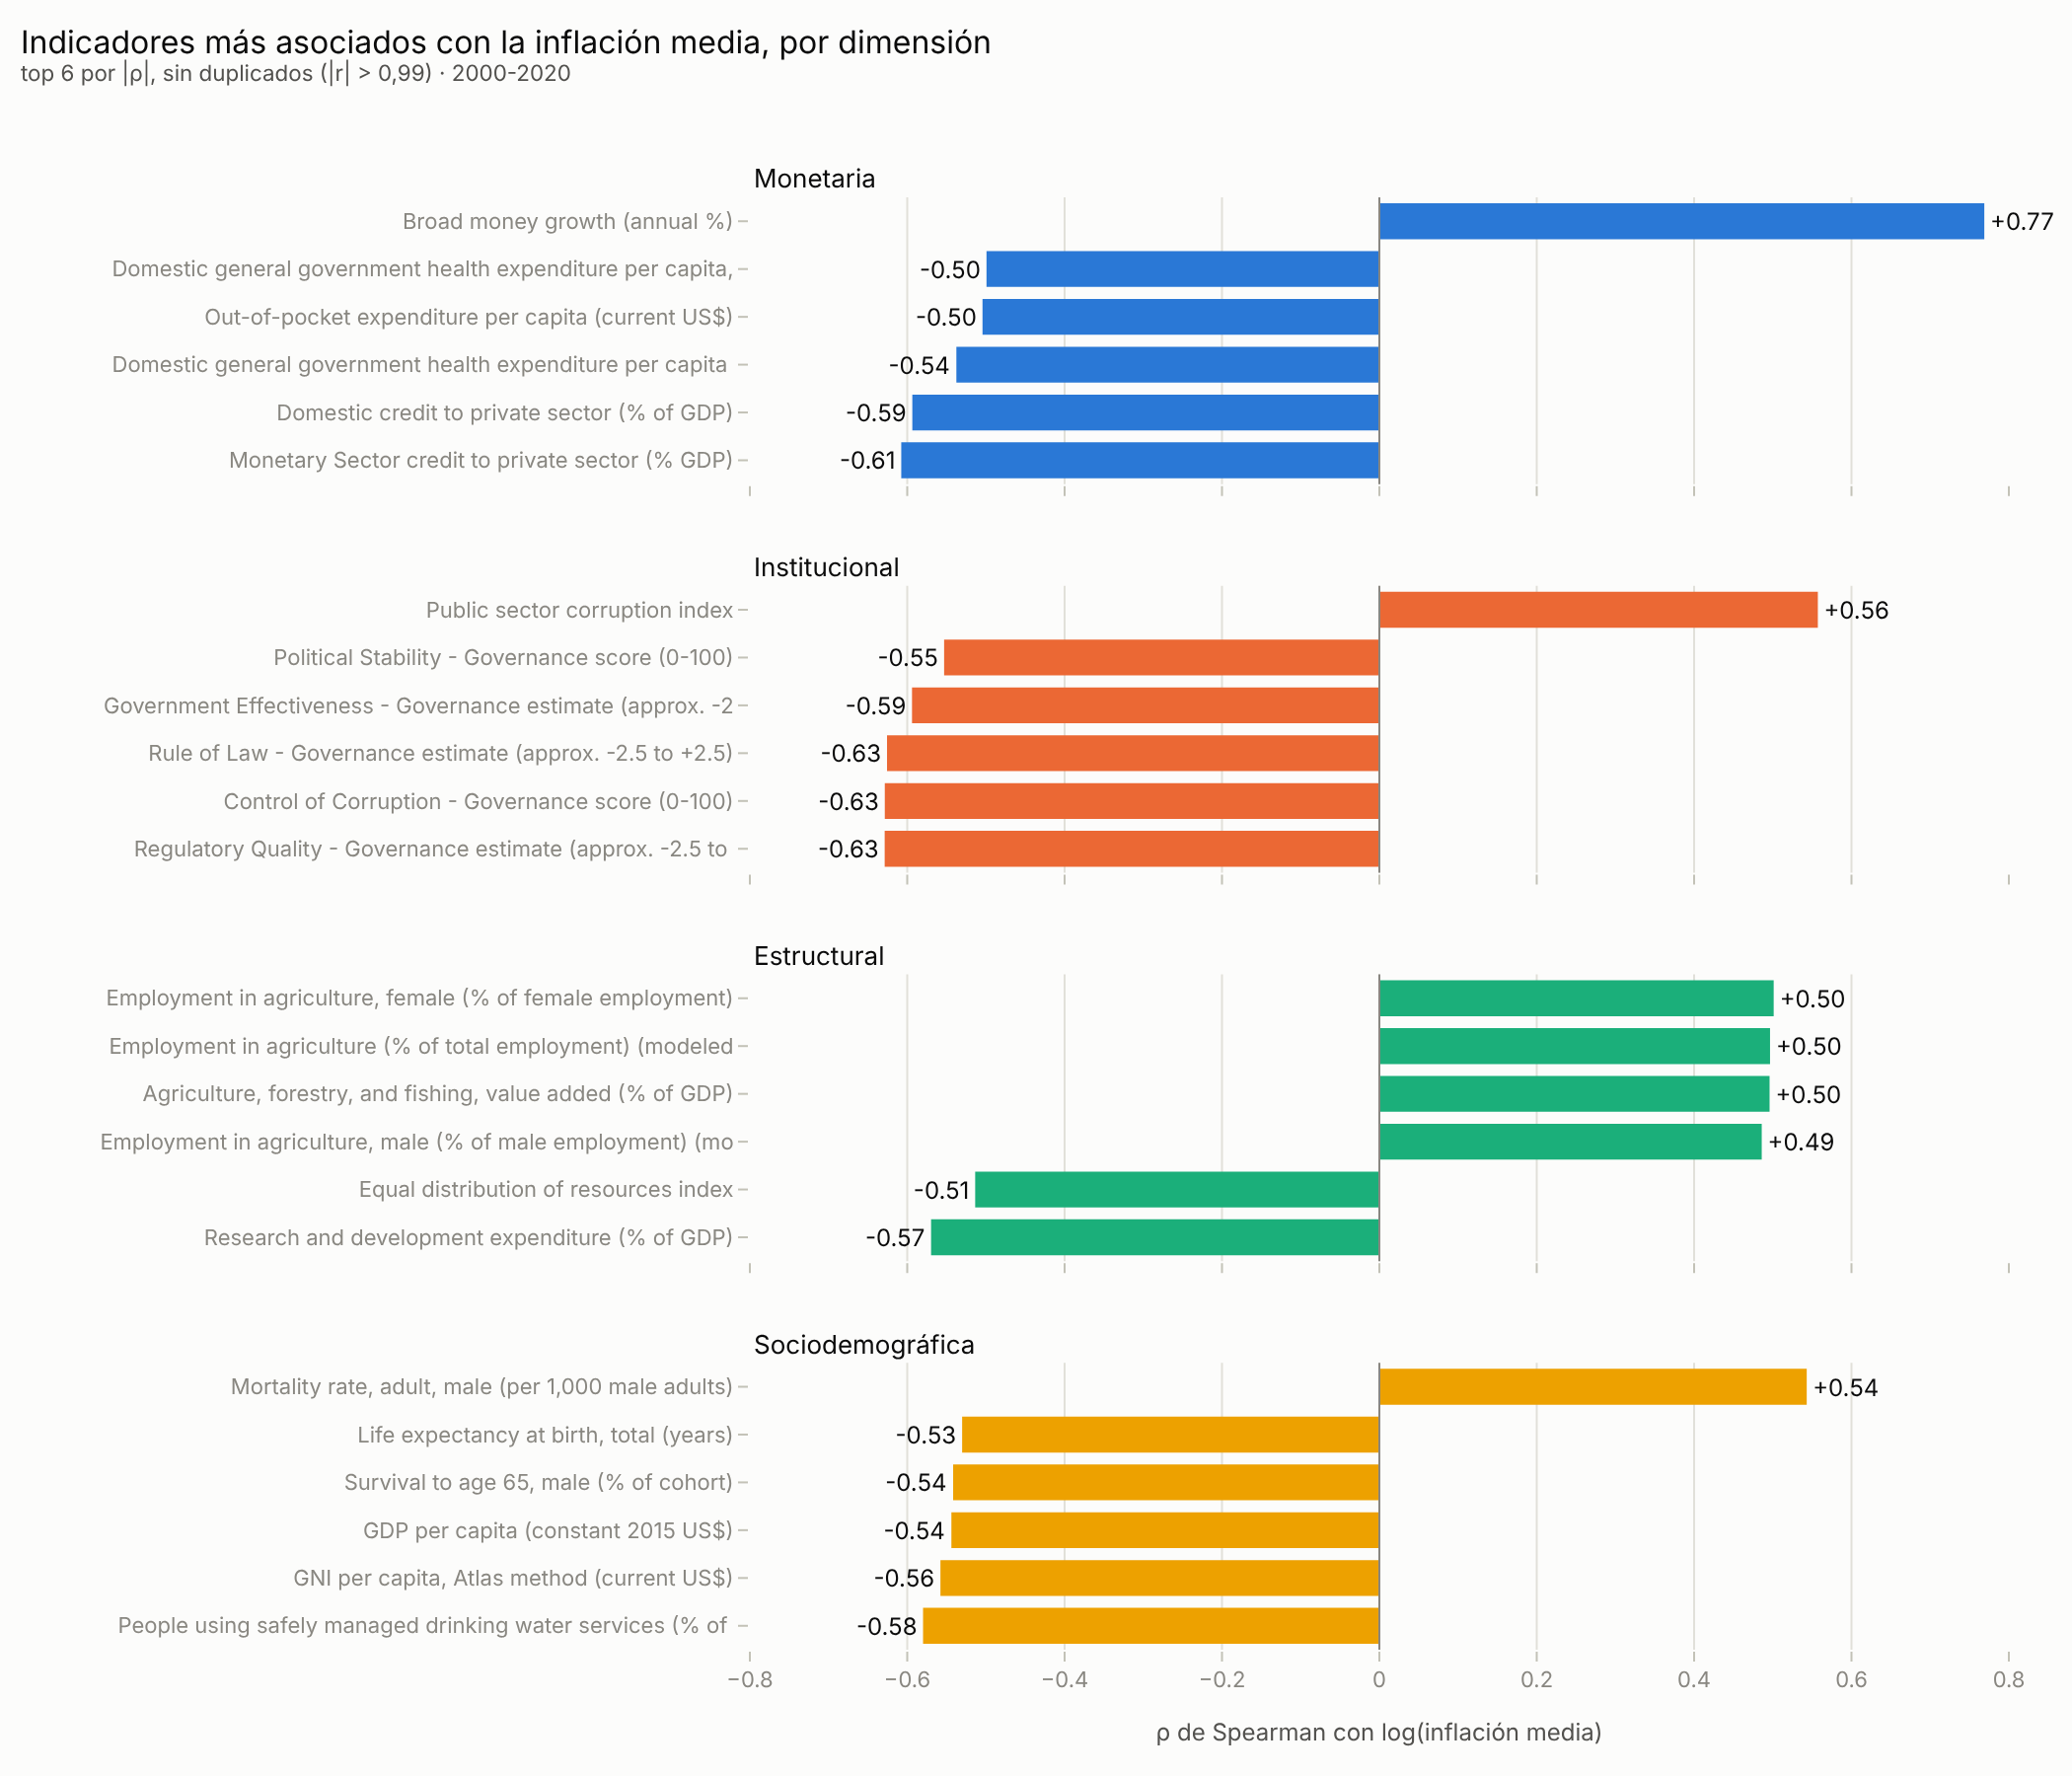

dimension
ESTRUCTURAL         30.4
INSTITUCIONAL       60.0
MONETARIA           30.5
SOCIODEMOGRAFICA    65.6
Name: % con |ρ|>0,3, dtype: float64
dimension
ESTRUCTURAL         0.57
INSTITUCIONAL       0.63
MONETARIA           0.77
SOCIODEMOGRAFICA    0.58
Name: max |ρ|, dtype: float64


In [5]:
y = np.log(target["media"]).dropna()
rows = []
for c in feat.loc[feat["estadistico"] == "media", "col"]:
    s = X[c].dropna()
    idx = s.index.intersection(y.index)
    if len(idx) >= 100:
        rows.append({"col": c, "rho": s.loc[idx].corr(y.loc[idx], method="spearman"), "n": len(idx)})
assoc = pd.DataFrame(rows).merge(feat, on="col")
assoc["nombre"] = assoc["codigo"].map(meta).fillna(assoc["codigo"]).str.slice(0, 58)
picked = []
for dim, g in assoc.assign(a=assoc["rho"].abs()).sort_values("a", ascending=False).groupby("dimension"):
    chosen = []
    for c in g["col"]:
        if all(abs(Z[c].corr(Z[o])) < 0.99 for o in chosen):
            chosen.append(c)
        if len(chosen) == 6:
            break
    picked += chosen
top = assoc[assoc["col"].isin(picked)]
fig = make_subplots(rows=4, cols=1, subplot_titles=[DIM_LABELS[d] for d in DIMENSION_COLORS], vertical_spacing=0.07, shared_xaxes=True)
for i, dim in enumerate(DIMENSION_COLORS, start=1):
    g = top[top["dimension"] == dim].sort_values("rho")
    fig.add_bar(x=g["rho"], y=g["nombre"], orientation="h", marker_color=DIMENSION_COLORS[dim], showlegend=False,
                text=g["rho"].map(lambda v: f"{v:+.2f}"), textposition="outside", cliponaxis=False,
                hovertemplate="%{y}: ρ = %{x:.2f}<extra></extra>", row=i, col=1)
    fig.update_yaxes(showgrid=False, row=i, col=1)
fig.add_vline(x=0, line=dict(color=INK_MUTED, width=1))
fig.update_xaxes(range=[-0.8, 0.8], title_text="ρ de Spearman con log(inflación media)", row=4, col=1)
fig.update_annotations(font_size=13, x=0, xanchor="left")
fig.update_layout(title=subtitle("Indicadores más asociados con la inflación media, por dimensión", "top 6 por |ρ|, sin duplicados (|r| > 0,99) · 2000-2020"),
                  margin=dict(l=380), bargap=0.25)
show(fig, "04_asociaciones_inflacion", width=1050, height=900)
print(assoc.groupby("dimension")["rho"].agg(lambda s: (s.abs() > 0.3).mean()).mul(100).round(1).rename("% con |ρ|>0,3"))
print(assoc.groupby("dimension")["rho"].agg(lambda s: s.abs().max()).round(2).rename("max |ρ|"))

**Interpretación (descriptiva, no causal).**

- **Monetaria**: la asociación más fuerte es el crecimiento del dinero amplio (ρ = +0,77), el mecanismo de la teoría cuantitativa. La profundidad financiera (crédito al sector privado) se asocia negativamente (ρ ≈ −0,6). Las tasas de interés, que daban asociaciones aún más altas, quedaron fuera del universo: la real se calcula con el deflactor y las nominales incorporan la inflación esperada (efecto Fisher), de modo que su correlación con la inflación es en buena parte mecánica.
- **Institucional**: los indicadores de gobernanza del WGI (Estado de derecho, control de la corrupción, calidad regulatoria, efectividad del gobierno) se asocian con menor inflación (ρ ≈ −0,55 a −0,63), y la corrupción del sector público con mayor inflación (+0,56).
- **Estructural**: mayor peso del agro en el empleo y el producto se asocia con más inflación (+0,50). El gasto en I+D y la igualdad en la distribución de recursos (V-Dem), con menos (−0,57 y −0,51).
- **Sociodemográfica**: acceso a agua segura, ingreso per cápita, esperanza de vida y supervivencia se asocian con menor inflación (−0,53 a −0,58).

La proporción de indicadores con |ρ| > 0,3 es mayor en la sociodemográfica (65%) y la institucional (60%) que en la monetaria (32%) y la estructural (30%). Esto no indica que las dimensiones no monetarias "expliquen más": refleja que muchas de ellas siguen un mismo gradiente de desarrollo, que a su vez está correlacionado con el perfil monetario. Por eso H2 y H3 se evalúan **controlando por lo monetario**: se pregunta qué aportan las otras dimensiones más allá de ese gradiente compartido.

## 4. Del universo de países a las muestras de análisis

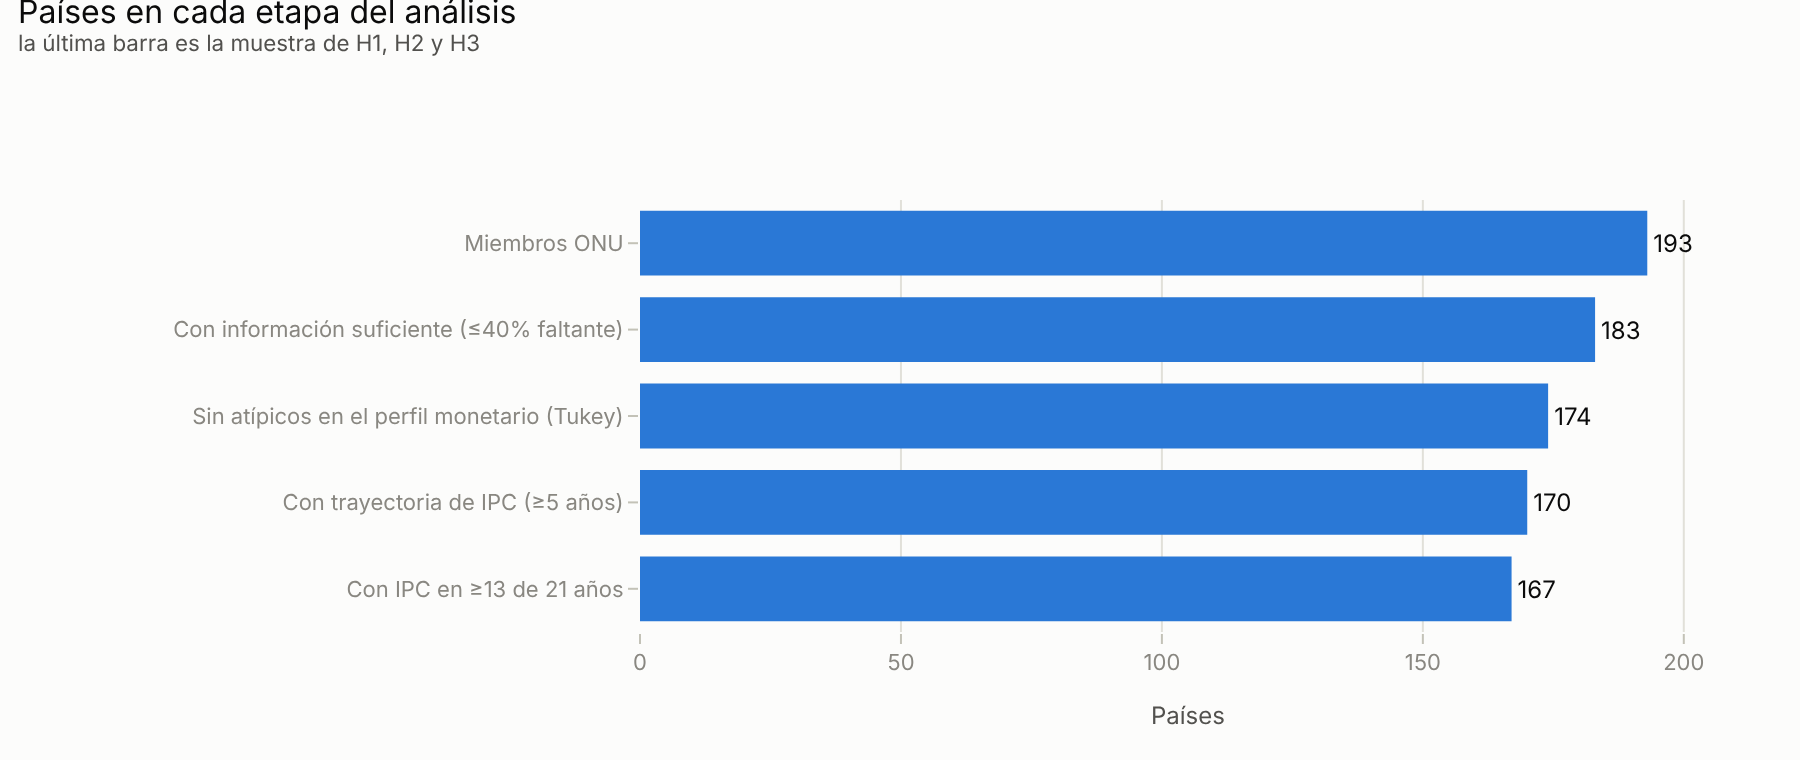

Atípicos monetarios: Timor-Leste (TLS), Sierra Leone (SLE), Libya (LBY), Eritrea (ERI), Zimbabwe (ZWE), Kiribati (KIR), South Sudan (SSD), Iceland (ISL), Equatorial Guinea (GNQ)
En clustering pero sin trayectoria de IPC: Argentina (ARG), Cuba (CUB), Somalia (SOM), Turkmenistan (TKM)
En clustering con serie de IPC corta: Uzbekistan (UZB), Lebanon (LBN), Venezuela (Bolivarian Republic of) (VEN)


In [6]:
clus = pd.read_csv(D / "clusters.csv", index_col=0)
dist = pd.read_csv(D / "clustering_distancias.csv", index_col=0)
steps = [("Miembros ONU", 193), ("Con información suficiente (≤40% faltante)", Z.shape[0]),
         ("Sin atípicos en el perfil monetario (Tukey)", len(clus)),
         ("Con trayectoria de IPC (≥5 años)", int(target.loc[clus.index, "media"].notna().sum())),
         (f"Con IPC en ≥{P['trayectorias']['min_anios_target']} de 21 años", int(targets.load().loc[clus.index, "media"].notna().sum()))]
fig = go.Figure(go.Bar(y=[s for s, _ in steps], x=[n for _, n in steps], orientation="h", marker_color=CATEGORICAL[0],
                       text=[n for _, n in steps], textposition="outside", cliponaxis=False))
fig.update_layout(title=subtitle("Países en cada etapa del análisis", "la última barra es la muestra de H1, H2 y H3"),
                  yaxis=dict(autorange="reversed", showgrid=False), xaxis=dict(range=[0, 210], title="Países"), margin=dict(l=320))
show(fig, "04_flujo_paises", height=380)
atip = dist[dist["atipico"]].sort_values("distancia_centroide", ascending=False)
print("Atípicos monetarios:", ", ".join(f"{members.loc[i, 'pais']} ({i})" for i in atip.index))
sin_ipc = target.loc[clus.index][target.loc[clus.index, "media"].isna()].index
print("En clustering pero sin trayectoria de IPC:", ", ".join(f"{members.loc[i, 'pais']} ({i})" for i in sin_ipc))
corta = targets.load().loc[clus.index]["media"].isna() & target.loc[clus.index, "media"].notna()
print("En clustering con serie de IPC corta:", ", ".join(f"{members.loc[i, 'pais']} ({i})" for i in corta[corta].index))

**Interpretación.** Las pruebas de hipótesis trabajan sobre 167 países. Desde el universo se pierden 10 países por información insuficiente, 9 por ser atípicos en el perfil monetario (Timor-Leste, Sierra Leona, Libia, Eritrea, Zimbabue, Kiribati, Sudán del Sur, Islandia y Guinea Ecuatorial), 4 por no tener IPC utilizable (Argentina, Cuba, Somalia y Turkmenistán) y 3 por tener una serie de IPC demasiado corta para describir el período (Venezuela, Uzbekistán y Líbano; ver notebook 03, sección 5). Los atípicos monetarios combinan dos tipos de casos: economías petroleras o en conflicto con estructuras fiscales y monetarias extremas, y economías muy pequeñas o con crisis financieras sistémicas (Islandia, 2008). Su influencia se evalúa en el notebook 08 volviendo a estimar las regresiones con ellos incluidos.